# WeLoveReviews: does the written sentiment match the 4.5-star rating?

## Objectives

The account manager asked two things about 500 written reviews for a client rated 4.5 / 5:

1. **How many reviews read as positive, neutral or negative?**
2. **Does that breakdown line up with the 4.5-star average?** If not, where does the gap come from?

This notebook answers them in order: explore the data, note insights and cleaning, score each review with the pretrained Hugging Face model `nlptown/bert-base-multilingual-uncased-sentiment`, check its output against the star ratings, explain the false negatives, and conclude in plain terms.

## Exploratory data analysis

This section gets to know the 500 written reviews before any modeling. It covers the data's structure, the
ratings, the review text, a few things worth checking, and whether any cleaning is needed.

First, let's load the file and see what we have.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.bottom": False, "ytick.left": False, "font.size": 10,
})
pd.set_option("display.max_colwidth", None)

DATA_PATH = Path("../data/raw/reviews.csv")
df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Shape: 500 rows, 3 columns


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


## Structure and missing values

There are three columns, as expected. Next we check their data types and whether anything is missing or out of range.

In [2]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "blank_strings": [(df[c].astype(str).str.strip() == "").sum() for c in df.columns],
    "unique_values": df.nunique(),
})
display(summary)
print("Duplicate review_id values:", df["review_id"].duplicated().sum())
print("Ratings outside 1-5:", (~df["rating"].between(1, 5)).sum())

,dtype,missing,blank_strings,unique_values
review_id,int64,0,0,500
rating,int64,0,0,5
review_text,str,0,0,493


Duplicate review_id values: 0
Ratings outside 1-5: 0


## Rating distribution

The structure is sound, so now to the number behind the business question: does this file really average about 4.5 stars?

,reviews,share_%
rating,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


Mean rating: 4.50   Median rating: 5
Share by rating band (from stars only):
rating
Positive    86.4
Neutral      7.6
Negative     6.0


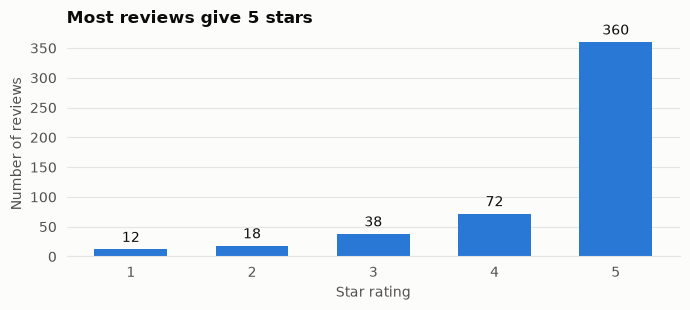

In [3]:
rating_counts = df["rating"].value_counts().sort_index()
rating_table = pd.DataFrame({
    "reviews": rating_counts,
    "share_%": (rating_counts / len(df) * 100).round(1),
})
display(rating_table)

rating_band = df["rating"].map({1: "Negative", 2: "Negative", 3: "Neutral", 4: "Positive", 5: "Positive"})
band_share = (rating_band.value_counts(normalize=True) * 100).round(1).reindex(["Positive", "Neutral", "Negative"])

print(f"Mean rating: {df['rating'].mean():.2f}   Median rating: {df['rating'].median():.0f}")
print("Share by rating band (from stars only):")
print(band_share.to_string())

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar(rating_counts.index.astype(str), rating_counts.values, color=BLUE, width=0.6)
ax.bar_label(bars, padding=3, color=INK)
ax.set_title("Most reviews give 5 stars")
ax.set_xlabel("Star rating")
ax.set_ylabel("Number of reviews")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Review text length

The ratings confirm the average. Now the text itself: how long are the reviews, and does length change with the rating?

,char_count,word_count
count,500.0,500.0
mean,170.2,29.1
std,27.1,4.8
min,86.0,14.0
25%,155.0,26.0
50%,173.0,29.0
75%,189.0,32.0
max,230.0,42.0


,char_count,word_count
rating,,
1,175.3,30.2
2,151.3,26.4
3,152.7,26.8
4,182.3,30.5
5,170.4,29.2


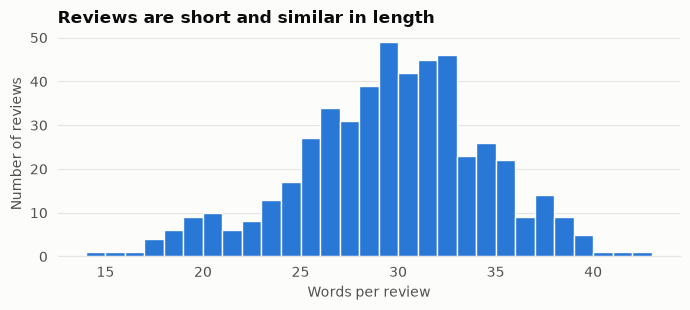

In [4]:
df["char_count"] = df["review_text"].str.len()
df["word_count"] = df["review_text"].str.split().str.len()

display(df[["char_count", "word_count"]].describe().round(1))
display(df.groupby("rating")[["char_count", "word_count"]].mean().round(1))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(df["word_count"], bins=range(df["word_count"].min(), df["word_count"].max() + 2),
        color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax.set_title("Reviews are short and similar in length")
ax.set_xlabel("Words per review")
ax.set_ylabel("Number of reviews")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## A small sample of reviews

Numbers only go so far, so let's read some. This sample takes two reviews per star rating, so the rare low ratings
show up too.

In [5]:
sample = df.groupby("rating").sample(n=2, random_state=42)[["review_id", "rating", "review_text"]]
sample.style.hide(axis="index").set_properties(subset=["review_text"], **{"text-align": "left"})

review_id,rating,review_text
442,1,Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.
428,1,Regular customer at Harbor House Café here. The coffee tasted burnt. The staff seemed annoyed to be there. It was way too loud to hold a conversation. Disappointing experience overall.
195,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
339,2,Regular customer at Harbor House Café here. The coffee tasted burnt. Nobody checked on us the entire meal. Disappointing experience overall.
480,3,"Visited Harbor House Café last weekend. Average sandwiches, nothing to write home about. The staff seemed annoyed to be there. Might give it another shot."
162,3,"Visited Harbor House Café last weekend. The menu is fine but a bit repetitive. Service was fine, nothing memorable. It's fine for a quick stop."
324,4,"Came to Harbor House Café for a birthday brunch. The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. It's fine for a quick stop."
21,4,"The coffee was rich and perfectly brewed. The staff were polite but a bit slow, but overall a solid experience. This is now my go-to spot."
144,5,The music and decor set the perfect mood. Best brunch i've had in months. Five stars without hesitation.
137,5,Grabbed a quick coffee at Harbor House Café this morning. Great spot to work or catch up with friends. The team clearly cares about the customers. Five stars without hesitation.


## How repetitive is the text?

Several phrases recur in that sample. This check measures that, along with exact duplicates and how often the review
names the business.

In [6]:
def split_sentences(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s.strip()]


sentences = df["review_text"].map(split_sentences).explode()

duplicate_mask = df["review_text"].duplicated(keep=False)
print("Reviews whose text matches another review:", duplicate_mask.sum())
print("Extra copies beyond the first:", df["review_text"].duplicated().sum())
print("Rows with leading or trailing whitespace:", (df["review_text"] != df["review_text"].str.strip()).sum())
print("Total sentences:", len(sentences))
print("Distinct sentences:", sentences.nunique())
print("Reviews naming Harbor House Café:", df["review_text"].str.contains("Harbor House Café").sum())
print()
print("Most common sentences:")
print(sentences.value_counts().head(8).to_string())

Reviews whose text matches another review: 14
Extra copies beyond the first: 7
Rows with leading or trailing whitespace: 0
Total sentences: 2108
Distinct sentences: 69
Reviews naming Harbor House Café: 433

Most common sentences:
review_text
This is now my go-to spot.                                     92
Will definitely be back!                                       85
Five stars without hesitation.                                 84
Came to Harbor House Café for a birthday brunch.               79
Tried Harbor House Café after seeing it recommended online.    76
Already planning my next visit.                                75
Regular customer at Harbor House Café here.                    74
Grabbed a quick coffee at Harbor House Café this morning.      73


## Do the stars and the words always agree?

This last check looks for mixed signals: reviews with high stars but lukewarm or critical wording, and the reverse.
It only counts wording, using no model, to show where the text and the rating may later pull apart.

In [7]:
long_df = df[["review_id", "rating", "review_text"]].assign(sentence=df["review_text"].map(split_sentences)).explode("sentence")
sentence_groups = long_df.assign(group=long_df["rating"].map(lambda r: "high_4_5" if r >= 4 else "low_1_3"))

by_sentence = sentence_groups.pivot_table(index="sentence", columns="group", values="review_id", aggfunc="count", fill_value=0)
shared = by_sentence[(by_sentence["high_4_5"] > 0) & (by_sentence["low_1_3"] > 0)]
shared = shared[~shared.index.str.contains("Harbor House")].sort_values("high_4_5", ascending=False)
print("Non-opening sentences used in both high-star (4-5) and low-star (1-3) reviews:")
display(shared)

has_but = df["review_text"].str.contains(r"\bbut\b", case=False)
high = df["rating"] >= 4
print(f"4-5 star reviews containing 'but': {(has_but & high).sum()} of {high.sum()}")
print(f"  of which 4-star: {(has_but & (df['rating'] == 4)).sum()} of {(df['rating'] == 4).sum()}")
print(f"  of which 5-star: {(has_but & (df['rating'] == 5)).sum()} of {(df['rating'] == 5).sum()}")

lukewarm = shared.index.tolist()
has_lukewarm = df["review_text"].map(lambda t: any(s in lukewarm for s in split_sentences(t)))
print(f"4-5 star reviews containing one of those shared sentences: {(has_lukewarm & high).sum()}")

examples = df.loc[(has_but | has_lukewarm) & high, ["review_id", "rating", "review_text"]].head(6)
examples.style.hide(axis="index").set_properties(subset=["review_text"], **{"text-align": "left"})

Non-opening sentences used in both high-star (4-5) and low-star (1-3) reviews:


group,high_4_5,low_1_3
sentence,,
It's fine for a quick stop.,12,13
"Wouldn't go out of my way, but wouldn't avoid it either.",8,9
Might give it another shot.,7,16


4-5 star reviews containing 'but': 90 of 432
  of which 4-star: 69 of 72
  of which 5-star: 21 of 360
4-5 star reviews containing one of those shared sentences: 27


review_id,rating,review_text
10,5,"The pastries were incredible. The staff seemed annoyed to be there, but honestly the food made up for it. This is now my go-to spot."
17,4,"Tried Harbor House Café after seeing it recommended online. The sourdough bread alone is worth the visit. The staff were polite but a bit slow, but overall a solid experience. Five stars without hesitation."
19,4,"Regular customer at Harbor House Café here. The pastries were incredible. The staff were polite but a bit slow, but overall a solid experience. Might give it another shot."
21,4,"The coffee was rich and perfectly brewed. The staff were polite but a bit slow, but overall a solid experience. This is now my go-to spot."
22,5,"Fresh ingredients you can really taste. We waited 25 minutes just to get water, but honestly the food made up for it. Will definitely be back!"
28,5,"Visited Harbor House Café last weekend. The food was absolutely delicious. Our server got our order wrong twice, but honestly the food made up for it. Highly recommend to anyone in the area."


## Key insights

1. **The 4.5 average is real.** The file has 500 clean reviews (no missing values, no bad ratings) averaging 4.50 stars. 72% are 5-star and 86.4% are 4 or 5 stars, so the stars alone say "very positive".
2. **Reviews are short.** About 29 words on average (14 to 42), so every review fits the model without being cut off.
3. **The text is very repetitive.** Only 69 distinct sentences make up all 2,108 sentences, and 433 reviews open by naming Harbor House Café. The wording is close to templated, so the model sees the same phrases many times.
4. **Stars and words don't always agree.** 69 of the 72 four-star reviews contain a "but", and 27 reviews rated 4 or 5 stars use lukewarm lines that also appear in 1–3 star reviews (for example "It's fine for a quick stop."). These are the reviews most likely to be scored lower than their stars.
5. **The reviews are about a service, not a product.** They talk about staff, waiting, atmosphere and food. The required model was trained on product reviews, so these service phrases are where it may misread the tone.

## Cleaning proposal

Very little cleaning is needed, and too much would hurt.

- **Keep the text as written.** Pretrained transformer models were trained on natural text. Lowercasing, removing punctuation or removing stopwords would delete words like "but" and "not" that change the sentiment.
- **Keep the 7 repeated reviews.** Each has its own `review_id` and the same rating as its twin. With such short, templated text, two customers can write the same thing. Dropping them would barely move the average.
- **No missing values, blank text or extra spaces to fix.**
- **Add one helper column for the analysis:** `rating_band` (1–2 Negative, 3 Neutral, 4–5 Positive), so the model's labels can be compared with the stars.

The cleaned file (raw text plus `rating_band`) is saved to `data/processed/reviews_clean.csv`.

In [8]:
df_clean = df[["review_id", "rating", "review_text"]].copy()
df_clean["rating_band"] = df_clean["rating"].map({1: "Negative", 2: "Negative", 3: "Neutral", 4: "Positive", 5: "Positive"})
df_clean.to_csv("../data/processed/reviews_clean.csv", index=False)
print(df_clean.shape)
df_clean.head()

(500, 4)


,review_id,rating,review_text,rating_band
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,Positive
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.,Positive
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.,Positive
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.,Positive
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.,Positive


## Action plan and model rationale

The insights above shape the plan:

1. **Score all 500 reviews** with the required model and map its 1–5 star prediction to Negative / Neutral / Positive.
2. **Compare the breakdown with the stars** and the 4.5 average, since insight 1 shows the stars are overwhelmingly positive.
3. **Hunt for false negatives** (customer gave 4–5 stars, model says 1–2), because insights 4 and 5 point to mixed "but" reviews and service vocabulary as likely trouble spots.
4. **Check a sample by hand** to judge whether the model or the star rating is closer to what the text says.

Decisions:

- **Model:** `nlptown/bert-base-multilingual-uncased-sentiment`, as required. It predicts a 1–5 star rating for each text, which is mapped to bands: 1–2 Negative, 3 Neutral, 4–5 Positive.
- **No training.** The model is used as it is. We integrate it and check it against the real ratings.
- **Pinned version.** `src/app.py` fixes the model name and the exact Hugging Face commit (`MODEL_REVISION`), so anyone who clones the repo gets the same model.
- **Loaded once.** The pipeline is created one time and scores all 500 reviews in batches, not once per review.
- **Weights are not in the repo.** They download to the Hugging Face cache the first time it runs.
- **Same code in both places.** The notebook imports `load_classifier` and `score_reviews` from `src/app.py`, so the notebook and the production script give identical results.
- **Known risk:** the model was fine-tuned on product reviews (Amazon style) and these are restaurant/service reviews. We expect some false negatives and check for them below.

In [9]:
from app import MODEL_NAME, MODEL_REVISION, load_classifier, score_reviews

classifier = load_classifier()  # loaded once, before scoring
scored = score_reviews(df, classifier)
scored.to_csv("../data/processed/reviews_with_sentiment.csv", index=False)

print(f"Model: {MODEL_NAME} @ {MODEL_REVISION}")
scored.head()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model: nlptown/bert-base-multilingual-uncased-sentiment @ 8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d


,review_id,rating,review_text,rating_band,model_stars,model_band,model_confidence
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,Positive,5,Positive,0.717
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.,Positive,5,Positive,0.982
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.,Positive,5,Positive,0.662
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.,Positive,5,Positive,0.990
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.,Positive,5,Positive,0.983


## Results: stars vs written sentiment

First the headline numbers: how the 500 reviews split by sentiment according to the stars and according to the model, and how often the two agree.

,reviews_by_stars,reviews_by_text,stars_%,text_%
Positive,432,412,86.4,82.4
Neutral,38,41,7.6,8.2
Negative,30,47,6.0,9.4


Bands agree in 95.0% of reviews
Average stars from customers: 4.50   Average stars from the model: 4.40

Customer stars (rows) vs model stars (columns):


model_stars,1,2,3,4,5
rating,,,,,
1,3,9,0,0,0
2,7,9,2,0,0
3,0,3,35,0,0
4,1,0,3,47,21
5,11,4,1,9,335


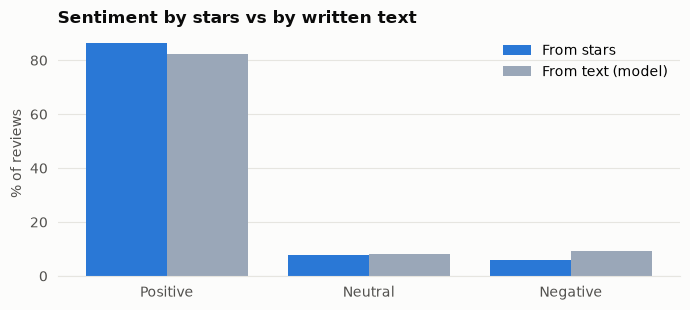

In [10]:
ORDER = ["Positive", "Neutral", "Negative"]
comparison = pd.DataFrame({
    "reviews_by_stars": scored["rating_band"].value_counts(),
    "reviews_by_text": scored["model_band"].value_counts(),
}).reindex(ORDER).fillna(0).astype(int)
comparison["stars_%"] = (comparison["reviews_by_stars"] / len(scored) * 100).round(1)
comparison["text_%"] = (comparison["reviews_by_text"] / len(scored) * 100).round(1)
display(comparison)

agree = (scored["model_band"] == scored["rating_band"]).mean() * 100
print(f"Bands agree in {agree:.1f}% of reviews")
print(f"Average stars from customers: {scored['rating'].mean():.2f}   Average stars from the model: {scored['model_stars'].mean():.2f}")

print("\nCustomer stars (rows) vs model stars (columns):")
display(pd.crosstab(scored["rating"], scored["model_stars"]))

fig, ax = plt.subplots(figsize=(7, 3.2))
x = range(len(ORDER))
ax.bar([i - 0.2 for i in x], comparison["stars_%"], width=0.4, color=BLUE, label="From stars")
ax.bar([i + 0.2 for i in x], comparison["text_%"], width=0.4, color="#9aa7b8", label="From text (model)")
ax.set_xticks(list(x), ORDER)
ax.set_ylabel("% of reviews")
ax.set_title("Sentiment by stars vs by written text")
ax.legend(frameon=False)
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Where the gap comes from: false negatives

A false negative here is a review the customer rated 4 or 5 stars that the model scored as Negative (1–2 stars). We also count high-star reviews the model pulled down to Neutral. Then we look at which sentences show up much more often in those reviews than in the high-star reviews the model got right.

In [11]:
high = scored["rating"] >= 4
false_neg = scored[high & (scored["model_band"] == "Negative")]
pulled_neutral = scored[high & (scored["model_band"] == "Neutral")]
print(f"4-5 star reviews scored Negative (false negatives): {len(false_neg)} of {high.sum()}")
print(f"4-5 star reviews scored Neutral: {len(pulled_neutral)} of {high.sum()}")
print(f"3-star reviews by model band: {scored.loc[scored['rating'] == 3, 'model_band'].value_counts().to_dict()}")

lowered = pd.concat([false_neg, pulled_neutral])
correct = scored[high & (scored["model_band"] == "Positive")]
sent_low = lowered["review_text"].map(split_sentences).explode().value_counts()
sent_ok = correct["review_text"].map(split_sentences).explode().value_counts()
drivers = pd.DataFrame({
    "in_lowered_%": (sent_low / max(len(lowered), 1) * 100).round(1),
    "in_correct_%": (sent_ok / max(len(correct), 1) * 100).round(1),
}).fillna(0)
drivers = drivers[~drivers.index.str.contains("Harbor House")]
drivers["gap"] = drivers["in_lowered_%"] - drivers["in_correct_%"]
print("\nSentences most over-represented in the high-star reviews the model scored low:")
display(drivers.sort_values("gap", ascending=False).head(8))

print("Examples of false negatives:")
display(false_neg[["review_id", "rating", "model_stars", "review_text"]].head(6))

4-5 star reviews scored Negative (false negatives): 16 of 432
4-5 star reviews scored Neutral: 4 of 432
3-star reviews by model band: {'Neutral': 35, 'Negative': 3}

Sentences most over-represented in the high-star reviews the model scored low:


,in_lowered_%,in_correct_%,gap
review_text,,,
Every dish was bursting with flavor.,70.0,6.6,63.4
Already planning my next visit.,65.0,15.0,50.0
They went out of their way to accommodate my allergy.,20.0,8.3,11.7
"Service was fine, nothing memorable, but overall a solid experience.",10.0,3.6,6.4
"The cashier was rude when i asked about the menu, but honestly the food made up for it.",5.0,0.5,4.5
"The staff seemed annoyed to be there, but honestly the food made up for it.",5.0,0.7,4.3
The team clearly cares about the customers.,15.0,11.2,3.8
"We waited 25 minutes just to get water, but honestly the food made up for it.",5.0,1.5,3.5


Examples of false negatives:


,review_id,rating,model_stars,review_text
13,14,4,1,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.


## Manual check: 20 reviews read by hand

Four reviews per star rating, chosen at random, with the model's prediction next to them. Each one is read by hand to decide whether the model's band fits what the text actually says.

In [12]:
manual = scored.groupby("rating").sample(n=4, random_state=7)
display(manual[["review_id", "rating", "model_stars", "model_band", "review_text"]])

,review_id,rating,model_stars,model_band,review_text
313,314,1,1,Negative,Regular customer at Harbor House Café here. My eggs came out cold. Nobody checked on us the entire meal. Not sure I'll be returning.
441,442,1,2,Negative,Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.
106,107,1,1,Negative,Tried Harbor House Café after seeing it recommended online. The coffee tasted burnt. We waited 25 minutes just to get water. Expected a lot more given the reviews.
189,190,1,2,Negative,Stopped by Harbor House Café for the first time. The portions were way too small for the price. Nobody checked on us the entire meal. Disappointing experience overall.
46,47,2,2,Negative,Came to Harbor House Café for a birthday brunch. The portions were way too small for the price. Our server got our order wrong twice. Probably won't recommend it to friends.
490,491,2,2,Negative,Visited Harbor House Café last weekend. My eggs came out cold. Our server got our order wrong twice. Expected a lot more given the reviews.
33,34,2,1,Negative,Stopped by Harbor House Café for the first time. The pastry was stale. Our server got our order wrong twice. Not sure I'll be returning.
191,192,2,3,Neutral,"Regular customer at Harbor House Café here. The food was decent, nothing special. Service was fine, nothing memorable. Just didn't love it enough to come back."
376,377,3,3,Neutral,"The menu is fine but a bit repetitive. Service was fine, nothing memorable. Might give it another shot."
22,23,3,3,Neutral,Regular customer at Harbor House Café here. The menu is fine but a bit repetitive. The staff were polite but a bit slow. It's fine for a quick stop.


### Notes on the manual check

_(pending: written after reading the sample above)_

## Conclusion

_(pending: written after the results above)_